# 04. Comparación de movilidad durante incidencias de Rodalies

## 1. Objetivo y metodología

Se estudian dos incidencias documentadas: **7 de febrero de 2025 (Y25-002)**, con ámbito R1/Maresme, y **5 de junio de 2025 (Y25-013)**, cuyo análisis territorial se conserva.

La referencia del Notebook 02 es la mediana de viajes de días del mismo día semanal. Ámbito: lunes a viernes, sin festivos oficiales de Cataluña y excluyendo julio/agosto de objetivos y controles; se excluyen todas las fechas documentadas en el Excel. Se usa ±42 días en el análisis retrospectivo y solo los 42 días anteriores en la comparación predictiva, con mínimo tres controles válidos.

Los percentiles son de viajes, descriptivos y sin significación causal. Telefónica incluye todos los modos de transporte; una relación OD no identifica viajes en tren ni recorridos ferroviarios.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import duckdb
import holidays
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "data/processed/telefonica/M2.parquet").is_file())
DATA_DIR = PROJECT_ROOT / "data"
M2_PATH = DATA_DIR / "processed/telefonica/M2.parquet"
INCIDENCIAS_PATH = DATA_DIR / "raw/rodalies/RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx"
con = duckdb.connect()
festivos_cat = holidays.country_holidays("ES", subdiv="CT", years=[2023, 2024, 2025])
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from analysis.rmove_indicators import (
    cargar_relaciones, calcular_indicadores, comparar_relaciones,
    seleccionar_controles, evaluar_mediana, MESES_EXCLUIDOS,
)
print("M2 encontrado:", M2_PATH.exists(), "| Excel encontrado:", INCIDENCIAS_PATH.exists())
from analysis.rmove_cases import (
    ficha_incidencia, evaluar_disponibilidad, analizar_robustez,
    conclusiones_caso, exportar_caso,
)

M2 encontrado: True | Excel encontrado: True


## 2. Incidencias documentadas

La descripción, tramo, líneas, horario y cautelas se recuperan del Excel original. Y25-002 corresponde al túnel Barcelona Sants–Plaça de Catalunya y afecta a varias líneas; el Maresme es el ámbito territorial de este estudio, no la ubicación de la avería. Se conservan las cautelas y la coincidencia con otro episodio del R2 que recoge el registro.

In [2]:
incidencias = pd.read_excel(INCIDENCIAS_PATH, sheet_name="Incidencias Barcelona")
incidencias["Fecha"] = pd.to_datetime(incidencias["Fecha"])
fechas_con_incidencias = set(incidencias["Fecha"].dt.normalize().dropna())
ids_seleccionados = ["Y25-002", "Y25-013"]
incidencias_seleccionadas = incidencias.loc[incidencias["ID"].isin(ids_seleccionados)].sort_values("Fecha")
display(incidencias_seleccionadas[["ID", "Fecha", "Líneas afectadas", "Lugar / tramo",
    "Causa documentada", "Afectación documentada", "Horario / duración", "Notas y cautelas", "URL verificable"]])
ficha_febrero = ficha_incidencia(incidencias, "Y25-002")
ficha_junio = ficha_incidencia(incidencias, "Y25-013")
output_dir = PROJECT_ROOT / "data/processed/rmove"

,ID,Fecha,Líneas afectadas,Lugar / tramo,Causa documentada,Afectación documentada,Horario / duración,Notas y cautelas,URL verificable
84,Y25-002,2025-02-07,R1; R3; R4; R7,Barcelona Sants–Plaça de Catalunya,Fallo en la infraestructura / señalización del...,Circulación por vía única y frecuencias reduci...,Desde antes de 07:00; resuelta ~10:15,El registro parlamentario atribuye a esta afec...,https://beteve.cat/mobilitat/divendres-negre-r...
95,Y25-013,2025-06-05,R1; R2; R3; R4,"Túnel ferroviario de Barcelona, cerca de Plaça...",Tren averiado en el túnel,Alteraciones en varias líneas centrales; 155 t...,14:25–16:14 (registro oficial),Una de las mayores afectaciones documentadas a...,https://www.3cat.cat/3catinfo/el-mapa-dels-ret...


## 3. Funciones generales reutilizables

In [3]:
def cargar_od(origen, destino, nombre):
    return cargar_relaciones(con, M2_PATH, {nombre: (origen, destino)})

def cargar_totales(fecha, ventana=56):
    datos = con.execute("""
        SELECT day, SUM(viajes) AS viajes_observados,
               COUNT(*) AS registros, AVG(viajes) AS viajes_por_registro,
               COUNT(DISTINCT (municipio_origen, municipio_destino)) AS n_od
        FROM read_parquet(?) WHERE day BETWEEN ? AND ?
        AND municipio_origen<>municipio_destino GROUP BY day ORDER BY day
    """, [str(M2_PATH), (fecha-pd.Timedelta(days=ventana)).date(),
          (fecha+pd.Timedelta(days=ventana)).date()]).df()
    datos["day"] = pd.to_datetime(datos["day"])
    return datos

def tabla_cobertura(datos, fecha):
    controles = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dia = datos.loc[datos["day"].eq(fecha)]
    if dia.empty or controles.empty:
        return pd.DataFrame()
    filas = []
    for campo in ["viajes_observados", "registros", "n_od", "viajes_por_registro"]:
        observado = dia[campo].iloc[0]
        mediana = controles[campo].median()
        filas.append({"Indicador": campo, "Observado": observado, "Mediana controles": mediana,
                      "Variacion (%)": 100*(observado/mediana-1) if mediana>0 else np.nan,
                      "N controles": len(controles)})
    return pd.DataFrame(filas)
def graficar_variacion(tabla, titulo, alto=7):
    orden = tabla.sort_values("variacion_observada_pct")
    fig, ax = plt.subplots(figsize=(12, alto))
    ax.barh(orden["Relacion"], orden["variacion_observada_pct"],
            color=["#b64026" if v<0 else "#087e86" for v in orden["variacion_observada_pct"]])
    ax.axvline(0, color="black", linewidth=1)
    ax.set(xlabel="Variación de viajes frente a la mediana (%)", ylabel="", title=titulo)
    ax.invert_yaxis(); ax.grid(axis="x", alpha=.25)
    plt.tight_layout(); plt.show()

def graficar_cobertura(datos, fecha, titulo):
    comparables = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dias = datos.loc[datos["day"].dt.day_of_week.eq(fecha.day_of_week)]
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for ax, campo in zip(axes, ["viajes_observados", "registros", "n_od"]):
        ax.plot(dias["day"], dias[campo], color="#798b96", marker="o", label="Mismo día semanal")
        ax.scatter(comparables["day"], comparables[campo], color="#087e86", label="Controles usados")
        ax.axvline(fecha, color="#e8700a", linestyle="--", label="Incidencia")
        ax.set_ylabel(campo); ax.grid(alpha=.25)
    axes[0].set_title(titulo); axes[0].legend()
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

def graficar_evolucion(movilidad, fecha, nombres):
    fig, axes = plt.subplots(len(nombres), 1, figsize=(12, 4*len(nombres)), sharex=True, squeeze=False)
    for ax, nombre in zip(axes[:, 0], nombres):
        grupo = movilidad.loc[movilidad["Relacion"].eq(nombre)].sort_values("day")
        dias = pd.date_range(fecha-pd.Timedelta(days=21), fecha+pd.Timedelta(days=21))
        refs = pd.DataFrame([calcular_indicadores(grupo, d, fechas_con_incidencias, festivos_cat)[0] for d in dias])
        medianas = refs["mediana_viajes_controles"].where(refs["estado"].eq("ok"))
        ax.plot(dias, refs["viajes_observados"], label="Observados", marker="o", markersize=3)
        ax.plot(dias, medianas, linestyle="--", label="Mediana retrospectiva")
        ax.axvline(fecha, color="#e8700a", linestyle=":")
        ax.set(title=nombre, ylabel="Viajes"); ax.legend(); ax.grid(alpha=.25)
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 4. Primer caso: 7 de febrero de 2025 · R1/Maresme

### 4.1. Descripción y ámbito

Se utiliza el episodio Y25-002 tal como está registrado en el Excel: fallo en infraestructura/señalización del túnel, circulación por vía única y frecuencias reducidas. La ficha que sigue muestra sus datos originales. La selección territorial comprende Barcelona, Mataró, Premià de Mar, El Masnou y Arenys de Mar y sus veinte relaciones dirigidas, incluidos ambos sentidos con Barcelona.

Los criterios de suficiencia son los mismos utilizados para junio: al menos 300 días observados y 100 viajes diarios de media en 2024, observación válida del día analizado y un mínimo de tres controles. Se publican también las exclusiones; no se sustituyen ausencias por ceros.

In [4]:
fecha_incidencia_febrero = pd.Timestamp(ficha_febrero["fecha"])
display(pd.DataFrame([ficha_febrero]).T)
municipios_maresme = {"08019": "Barcelona", "08121": "Mataró", "08172": "Premià de Mar",
                      "08118": "El Masnou", "08006": "Arenys de Mar"}
relaciones_maresme = {
    f"{no} → {nd}": (o, d)
    for o, no in municipios_maresme.items() for d, nd in municipios_maresme.items() if o != d
}
movilidad_maresme_candidata = cargar_relaciones(con, M2_PATH, relaciones_maresme)
disponibilidad_febrero = evaluar_disponibilidad(
    movilidad_maresme_candidata, relaciones_maresme, fecha_incidencia_febrero,
    fechas_con_incidencias, festivos_cat)
display(disponibilidad_febrero.sort_values("viajes_medios_2024").round(2))
por_municipio = disponibilidad_febrero.groupby("municipio_origen").agg(
    dias_minimos_2024=("dias_observados_2024", "min"),
    relaciones_candidatas=("Relacion", "count"), relaciones_seleccionadas=("seleccionada", "sum"))
por_municipio.insert(0, "municipio", por_municipio.index.map(municipios_maresme))
display(por_municipio)
nombres_validos = disponibilidad_febrero.loc[disponibilidad_febrero["seleccionada"], "Relacion"]
movilidad_febrero = movilidad_maresme_candidata.loc[movilidad_maresme_candidata["Relacion"].isin(nombres_validos)].copy()
print("Relaciones seleccionadas:", len(nombres_validos), "de", len(relaciones_maresme))
display(movilidad_febrero.loc[movilidad_febrero["day"].eq(fecha_incidencia_febrero),
    ["Relacion", "municipio_origen", "municipio_destino", "viajes_observados"]].sort_values("viajes_observados").round(2))

,0
id,Y25-002
fecha,2025-02-07
lineas_afectadas,R1; R3; R4; R7
tramo,Barcelona Sants–Plaça de Catalunya
causa,Fallo en la infraestructura / señalización del...
afectacion,Circulación por vía única y frecuencias reduci...
horario,Desde antes de 07:00; resuelta ~10:15
fuente,betevé y 3CatInfo
url,https://beteve.cat/mobilitat/divendres-negre-r...
cautelas,El registro parlamentario atribuye a esta afec...


,Relacion,municipio_origen,municipio_destino,dias_observados_2024,viajes_medios_2024,viajes_observados_fecha,n_controles,seleccionada,motivo
15,El Masnou → Arenys de Mar,08118,08006,365,89.92,78.0,9,False,Media de 2024 inferior a 100 viajes/día
19,Arenys de Mar → El Masnou,08006,08118,365,97.12,80.0,9,False,Media de 2024 inferior a 100 viajes/día
18,Arenys de Mar → Premià de Mar,08006,08172,365,166.99,174.0,9,True,Datos suficientes
11,Premià de Mar → Arenys de Mar,08172,08006,365,173.90,186.0,9,True,Datos suficientes
14,El Masnou → Premià de Mar,08118,08172,365,656.62,665.0,9,True,Datos suficientes
10,Premià de Mar → El Masnou,08172,08118,365,709.80,746.0,9,True,Datos suficientes
13,El Masnou → Mataró,08118,08121,365,1039.80,1063.0,9,True,Datos suficientes
6,Mataró → El Masnou,08121,08118,365,1080.65,1020.0,9,True,Datos suficientes
16,Arenys de Mar → Barcelona,08006,08019,365,2029.80,1609.0,9,True,Datos suficientes
3,Barcelona → Arenys de Mar,08019,08006,365,2230.64,2139.0,9,True,Datos suficientes


,municipio,dias_minimos_2024,relaciones_candidatas,relaciones_seleccionadas
municipio_origen,,,,
08006,Arenys de Mar,365,4,3
08019,Barcelona,365,4,4
08118,El Masnou,365,4,3
08121,Mataró,365,4,4
08172,Premià de Mar,365,4,4


Relaciones seleccionadas: 18 de 20


,Relacion,municipio_origen,municipio_destino,viajes_observados
3680,Arenys de Mar → Premià de Mar,08006,08172,174.0
16303,Premià de Mar → Arenys de Mar,08172,08006,186.0
11448,El Masnou → Premià de Mar,08118,08172,665.0
18245,Premià de Mar → El Masnou,08172,08118,746.0
14361,Mataró → El Masnou,08121,08118,1020.0
10477,El Masnou → Mataró,08118,08121,1063.0
767,Arenys de Mar → Barcelona,08006,08019,1609.0
4651,Barcelona → Arenys de Mar,08019,08006,2139.0
2709,Arenys de Mar → Mataró,08006,08121,2895.0
12419,Mataró → Arenys de Mar,08121,08006,3225.0


### 4.2. Volumen provincial y cobertura

Se comparan viajes, registros y OD disponibles con viernes comparables bajo los mismos criterios. Los cambios provinciales se presentan como contexto: no se presupone que el episodio tenga alcance exclusivamente local ni se asigna una causa a una variación de cobertura.

,Indicador,Observado,Mediana controles,Variacion (%),N controles
0,viajes_observados,4562952.00,4547481.00,0.34,9
1,registros,68758.00,68616.00,0.21,9
2,n_od,33567.00,33364.00,0.61,9
3,viajes_por_registro,66.36,66.11,0.39,9


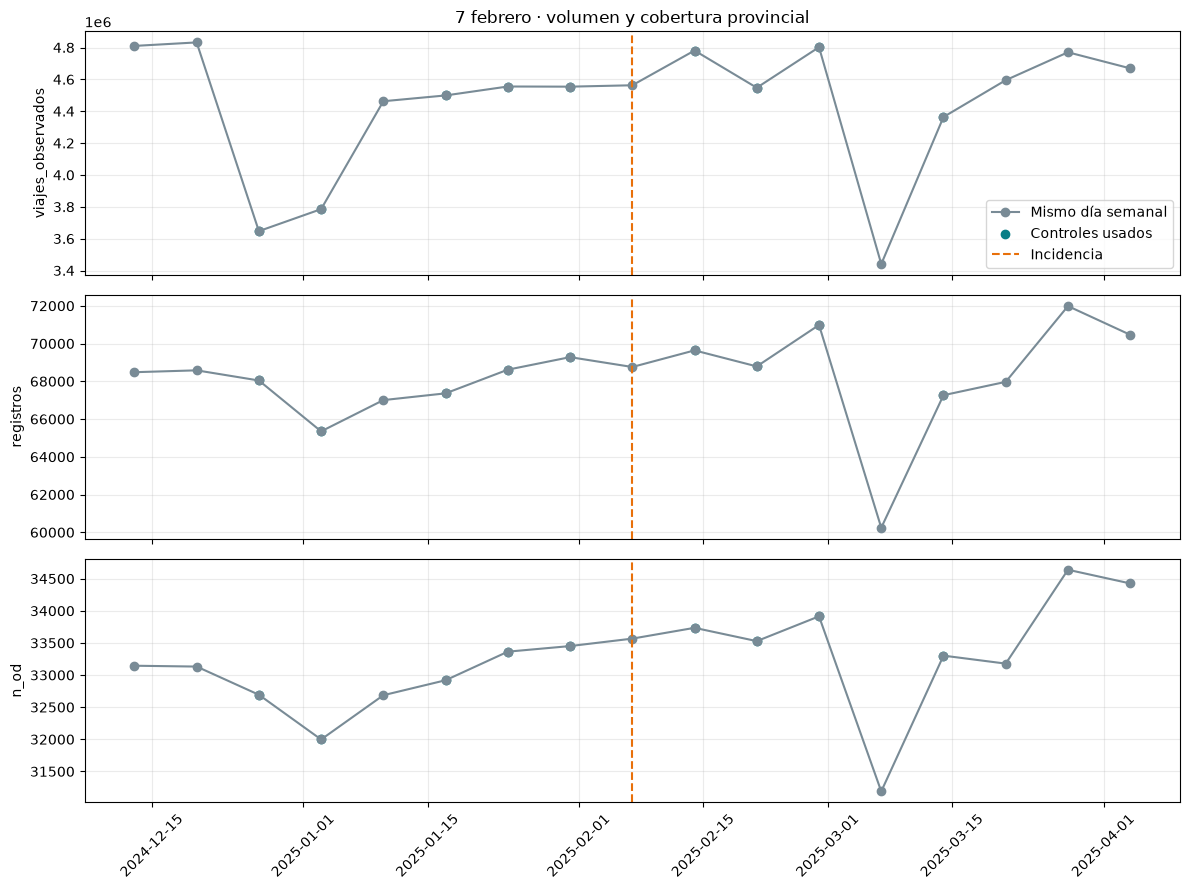

In [5]:
movilidad_provincial_febrero = cargar_totales(fecha_incidencia_febrero)
cobertura_febrero = tabla_cobertura(movilidad_provincial_febrero, fecha_incidencia_febrero)
display(cobertura_febrero.round(2))
graficar_cobertura(movilidad_provincial_febrero, fecha_incidencia_febrero,
                  "7 febrero · volumen y cobertura provincial")

### 4.3. Mediana de viernes comparables y variación de viajes

Tablas y gráficos con la misma definición que junio. Los rangos P25–P75 son descriptivos.

,Relacion,municipio_origen,municipio_destino,fecha,viajes_observados,mediana_viajes_controles,p25_viajes_controles,p75_viajes_controles,n_controles,variacion_observada_pct,diferencia_viajes,fuera_rango_intercuartil_viajes,modo_controles,ventana_dias,minimo_controles,estado
0,Mataró → El Masnou,08121,08118,2025-02-07,1020.0,1177.0,1165.0,1248.0,9,-13.34,-157.0,True,retrospectivo,42,3,ok
1,El Masnou → Mataró,08118,08121,2025-02-07,1063.0,1217.0,1161.0,1260.0,9,-12.65,-154.0,True,retrospectivo,42,3,ok
2,Barcelona → Arenys de Mar,08019,08006,2025-02-07,2139.0,2325.0,2262.0,2377.0,9,-8.00,-186.0,True,retrospectivo,42,3,ok
3,Arenys de Mar → Mataró,08006,08121,2025-02-07,2895.0,3096.0,2905.0,3238.0,9,-6.49,-201.0,True,retrospectivo,42,3,ok
4,El Masnou → Premià de Mar,08118,08172,2025-02-07,665.0,701.0,632.0,773.0,9,-5.14,-36.0,False,retrospectivo,42,3,ok
5,Barcelona → El Masnou,08019,08118,2025-02-07,4574.0,4811.0,4597.0,4882.0,9,-4.93,-237.0,True,retrospectivo,42,3,ok
6,Arenys de Mar → Barcelona,08006,08019,2025-02-07,1609.0,1659.0,1639.0,1757.0,9,-3.01,-50.0,True,retrospectivo,42,3,ok
7,El Masnou → Barcelona,08118,08019,2025-02-07,4493.0,4605.0,4542.0,4663.0,9,-2.43,-112.0,True,retrospectivo,42,3,ok
8,Premià de Mar → El Masnou,08172,08118,2025-02-07,746.0,763.0,718.0,787.0,9,-2.23,-17.0,False,retrospectivo,42,3,ok
9,Mataró → Arenys de Mar,08121,08006,2025-02-07,3225.0,3292.0,3117.0,3587.0,9,-2.04,-67.0,False,retrospectivo,42,3,ok


Mataró → Barcelona | Fechas de control: ['2024-12-27', '2025-01-03', '2025-01-17', '2025-01-24', '2025-01-31', '2025-02-14', '2025-02-21', '2025-02-28', '2025-03-14']
Barcelona → Mataró | Fechas de control: ['2024-12-27', '2025-01-03', '2025-01-17', '2025-01-24', '2025-01-31', '2025-02-14', '2025-02-21', '2025-02-28', '2025-03-14']


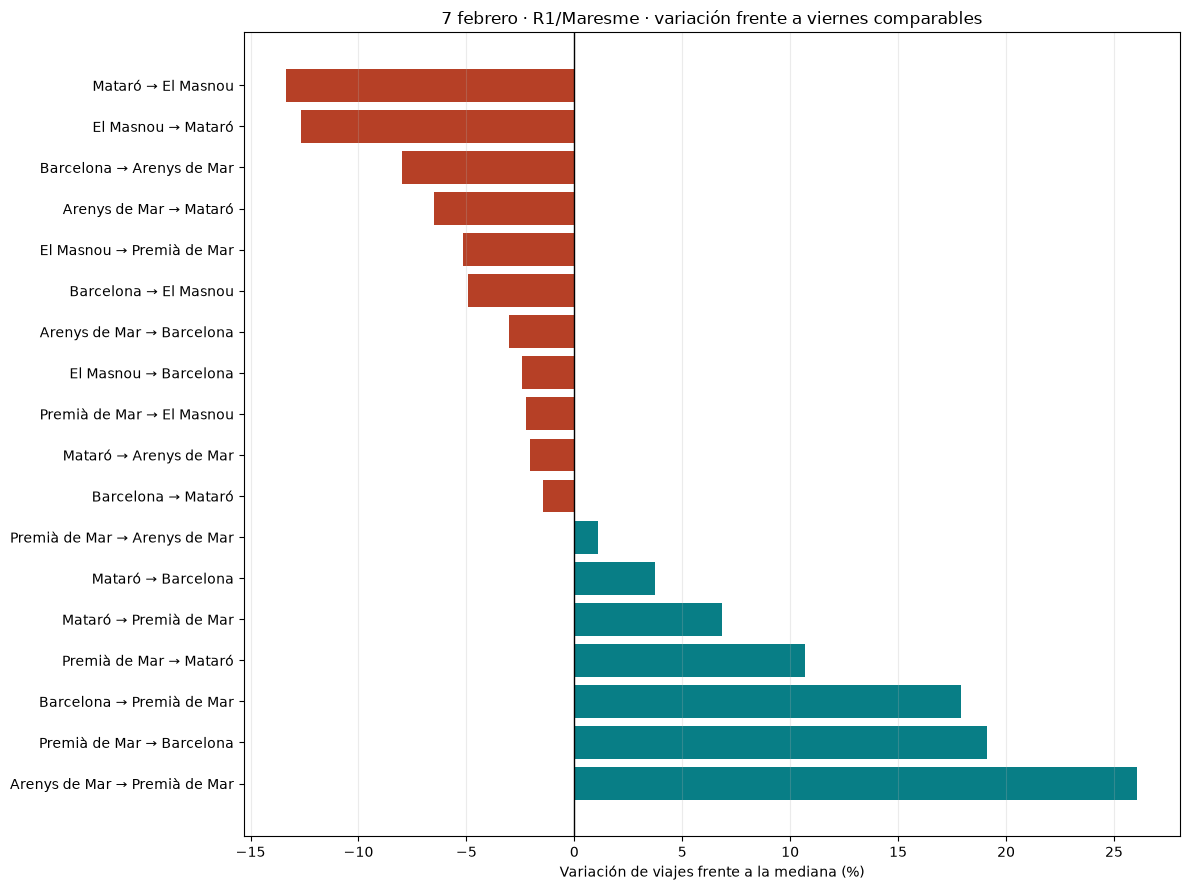

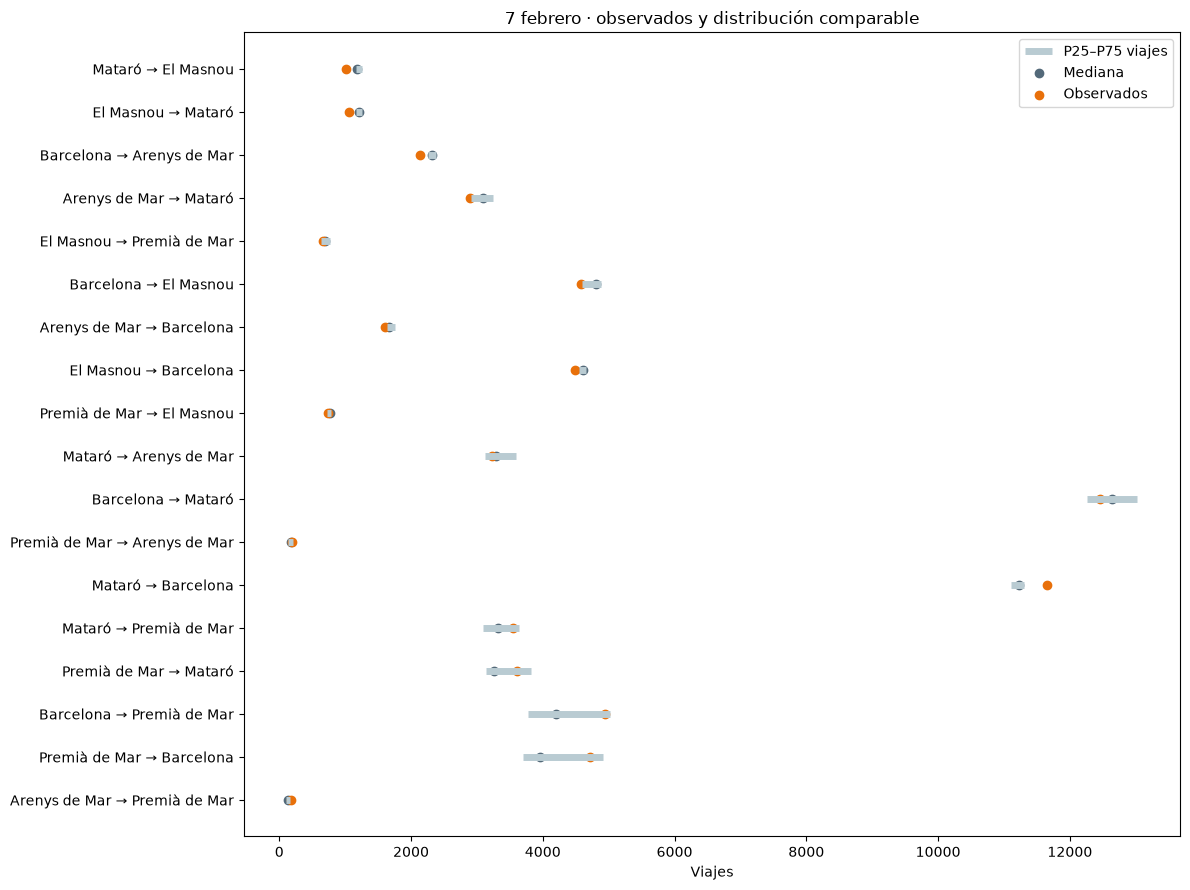

In [6]:
resultados_febrero = comparar_relaciones(
    movilidad_febrero, fecha_incidencia_febrero, fechas_con_incidencias, festivos_cat)
display(resultados_febrero.drop(columns="fechas_controles").round(2))
for nombre in ["Mataró → Barcelona", "Barcelona → Mataró"]:
    fila = resultados_febrero.loc[resultados_febrero["Relacion"].eq(nombre)].iloc[0]
    print(nombre, "| Fechas de control:", fila["fechas_controles"])
graficar_variacion(resultados_febrero, "7 febrero · R1/Maresme · variación frente a viernes comparables", alto=9)
orden = resultados_febrero.sort_values("variacion_observada_pct")
fig, ax = plt.subplots(figsize=(12, 9))
y = np.arange(len(orden))
ax.hlines(y, orden["p25_viajes_controles"], orden["p75_viajes_controles"], color="#b9cbd2", linewidth=5, label="P25–P75 viajes")
ax.scatter(orden["mediana_viajes_controles"], y, color="#536979", label="Mediana")
ax.scatter(orden["viajes_observados"], y, color="#e8700a", label="Observados")
ax.set_yticks(y, orden["Relacion"]); ax.invert_yaxis()
ax.set(xlabel="Viajes", title="7 febrero · observados y distribución comparable")
ax.legend(); plt.tight_layout(); plt.show()

### 4.4. Robustez y evolución temporal

Se muestran controles anteriores y retrospectivos por separado, ventanas de 28/42/56 días y series reales con ausencias sin imputar.

,Relacion,variacion_observada_pct_retrospectivo,n_controles_retrospectivo,variacion_observada_pct_predictivo,n_controles_predictivo
0,Mataró → El Masnou,-13.34,9,-12.45,5
1,El Masnou → Mataró,-12.65,9,-8.44,5
2,Barcelona → Arenys de Mar,-8.00,9,-6.06,5
3,Arenys de Mar → Mataró,-6.49,9,-5.58,5
4,El Masnou → Premià de Mar,-5.14,9,-1.63,5
5,Barcelona → El Masnou,-4.93,9,-0.50,5
6,Arenys de Mar → Barcelona,-3.01,9,-2.90,5
7,El Masnou → Barcelona,-2.43,9,-1.08,5
8,Premià de Mar → El Masnou,-2.23,9,3.32,5
9,Mataró → Arenys de Mar,-2.04,9,-0.15,5


,Relacion,modo_controles,ventana_dias,n_controles,variacion_observada_pct
0,Mataró → El Masnou,predictivo,28,3,-15.91
1,El Masnou → Mataró,predictivo,28,3,-15.63
2,Arenys de Mar → Barcelona,predictivo,28,3,-8.42
3,Barcelona → Arenys de Mar,predictivo,28,3,-8.00
4,Premià de Mar → Arenys de Mar,predictivo,28,3,-7.46
...,...,...,...,...,...
103,Premià de Mar → Arenys de Mar,retrospectivo,56,12,3.33
104,Mataró → Premià de Mar,retrospectivo,56,12,4.39
105,Barcelona → Premià de Mar,retrospectivo,56,12,14.14
106,Premià de Mar → Barcelona,retrospectivo,56,12,15.90


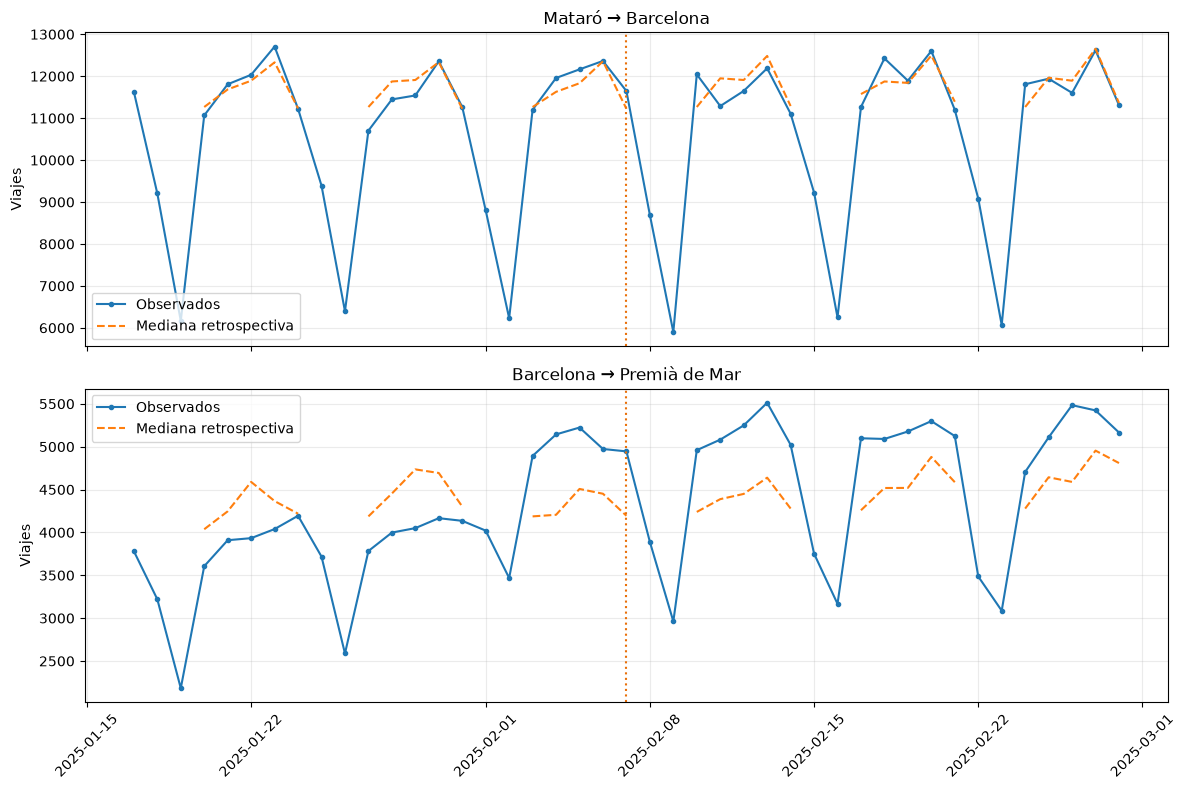

In [7]:
febrero_predictivo, robustez_febrero, sensibilidad_febrero = analizar_robustez(
    movilidad_febrero, fecha_incidencia_febrero, fechas_con_incidencias, festivos_cat, resultados_febrero)
display(robustez_febrero.round(2))
display(sensibilidad_febrero[["Relacion", "modo_controles", "ventana_dias", "n_controles", "variacion_observada_pct"]].round(2))
graficar_evolucion(movilidad_febrero, fecha_incidencia_febrero,
                  ["Mataró → Barcelona", "Barcelona → Premià de Mar"])

### 4.5. Conclusiones calculadas y exportación

Se exportan únicamente observaciones reales y estadísticas derivadas, junto con ficha del Excel, exclusiones, controles, cobertura, sensibilidad y series.

In [8]:
catalogo_febrero = [
    {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
    {"codigo": "08121", "nombre": "Mataró", "lat": 41.538, "lon": 2.445},
    {"codigo": "08172", "nombre": "Premià de Mar", "lat": 41.491, "lon": 2.357},
    {"codigo": "08118", "nombre": "El Masnou", "lat": 41.479, "lon": 2.317},
    {"codigo": "08006", "nombre": "Arenys de Mar", "lat": 41.581, "lon": 2.551},
]
for municipio in catalogo_febrero:
    municipio["precision"] = "Posición municipal aproximada; no es una estación"
for texto in conclusiones_caso(resultados_febrero, cobertura_febrero):
    print("•", texto)
salida_febrero = exportar_caso(
    output_dir=output_dir, fecha=fecha_incidencia_febrero, ficha=ficha_febrero,
    ambito="R1 / Maresme", municipios=catalogo_febrero, resultados=resultados_febrero,
    movilidad=movilidad_febrero, disponibilidad=disponibilidad_febrero,
    provincia=movilidad_provincial_febrero, cobertura=cobertura_febrero,
    robustez=robustez_febrero, sensibilidad=sensibilidad_febrero,
    fechas_incidencias=fechas_con_incidencias, festivos=festivos_cat,
    fuente_excel=str(INCIDENCIAS_PATH.relative_to(PROJECT_ROOT)))
print("Exportado: incidencia_2025_02_07.json")

• 18 relaciones con comparación válida: 11 por debajo de la mediana y 7 por encima.
• Menor variación: Mataró → El Masnou (-13,34 %).
• Mayor variación: Arenys de Mar → Premià de Mar (+26,09 %).
• Variación de viajes provinciales frente a sus días comparables: +0,34 %.
• Variación de registros de movilidad frente a sus días comparables: +0,21 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.


Exportado: incidencia_2025_02_07.json


## 5. Segundo caso: 5 de junio de 2025

### 5.1. Municipios y relaciones del corredor sur

Se mantienen los municipios, relaciones y criterios de volumen de 2024 del análisis de junio.

In [9]:

# Municipios candidatos del corredor sur
municipios_sur = {
    "08019": "Barcelona",
    "08169": "El Prat de Llobregat",
    "08301": "Viladecans",
    "08089": "Gavà",
    "08056": "Castelldefels"
}

# Relaciones dirigidas entre municipios distintos
relaciones_sur = []

for codigo_origen, nombre_origen in municipios_sur.items():
    for codigo_destino, nombre_destino in municipios_sur.items():

        if codigo_origen == codigo_destino:
            continue

        relaciones_sur.append({
            "municipio_origen": codigo_origen,
            "municipio_destino": codigo_destino,
            "Relacion": f"{nombre_origen} → {nombre_destino}"
        })

relaciones_sur = pd.DataFrame(relaciones_sur)

print("Relaciones candidatas:", len(relaciones_sur))
display(relaciones_sur)


Relaciones candidatas: 20


,municipio_origen,municipio_destino,Relacion
0,08019,08169,Barcelona → El Prat de Llobregat
1,08019,08301,Barcelona → Viladecans
2,08019,08089,Barcelona → Gavà
3,08019,08056,Barcelona → Castelldefels
4,08169,08019,El Prat de Llobregat → Barcelona
5,08169,08301,El Prat de Llobregat → Viladecans
6,08169,08089,El Prat de Llobregat → Gavà
7,08169,08056,El Prat de Llobregat → Castelldefels
8,08301,08019,Viladecans → Barcelona
9,08301,08169,Viladecans → El Prat de Llobregat


In [10]:

# Consultar volumen diario medio por relación OD en 2024
volumen_od = con.execute(
    """
    WITH viajes_diarios AS (
        SELECT
            municipio_origen,
            municipio_destino,
            day,
            SUM(viajes) AS viajes
        FROM read_parquet(?)
        WHERE day >= '2024-01-01'
          AND day < '2025-01-01'
          AND municipio_origen IN (SELECT unnest(?))
          AND municipio_destino IN (SELECT unnest(?))
          AND municipio_origen <> municipio_destino
        GROUP BY
            municipio_origen,
            municipio_destino,
            day
    )
    SELECT
        municipio_origen,
        municipio_destino,
        COUNT(*) AS dias_observados,
        AVG(viajes) AS viajes_medios,
        MEDIAN(viajes) AS viajes_medianos
    FROM viajes_diarios
    GROUP BY municipio_origen, municipio_destino
    """,
    [
        str(M2_PATH),
        list(municipios_sur.keys()),
        list(municipios_sur.keys())
    ]
).df()

# Incorporar los nombres de las relaciones
volumen_sur = relaciones_sur.merge(
    volumen_od,
    on=["municipio_origen", "municipio_destino"],
    how="left"
)

display(
    volumen_sur[
        ["Relacion", "dias_observados",
         "viajes_medios", "viajes_medianos"]
    ]
    .sort_values("viajes_medios", ascending=False)
    .round(2)
)


,Relacion,dias_observados,viajes_medios,viajes_medianos
0,Barcelona → El Prat de Llobregat,365,66753.29,67179.0
4,El Prat de Llobregat → Barcelona,365,64778.19,64348.0
3,Barcelona → Castelldefels,365,14111.94,14650.0
16,Castelldefels → Barcelona,365,13997.04,14498.0
1,Barcelona → Viladecans,365,13947.40,15099.0
8,Viladecans → Barcelona,365,13566.34,14905.0
12,Gavà → Barcelona,365,9437.04,10104.0
2,Barcelona → Gavà,365,9203.33,9924.0
18,Castelldefels → Viladecans,365,6038.30,6102.0
11,Viladecans → Castelldefels,365,5931.17,5967.0


In [11]:

UMBRAL_VIAJES = 100

relaciones_sur_analisis = volumen_sur[
    (volumen_sur["viajes_medios"] >= UMBRAL_VIAJES)
    & (volumen_sur["dias_observados"] >= 300)
].copy()

relaciones_sur_analisis = (
    relaciones_sur_analisis
    .sort_values("viajes_medios", ascending=False)
    .reset_index(drop=True)
)

print(
    "Relaciones seleccionadas:",
    len(relaciones_sur_analisis),
    "de",
    len(relaciones_sur)
)

display(
    relaciones_sur_analisis[
        ["Relacion", "viajes_medios", "dias_observados"]
    ].round(2)
)


Relaciones seleccionadas: 20 de 20


,Relacion,viajes_medios,dias_observados
0,Barcelona → El Prat de Llobregat,66753.29,365
1,El Prat de Llobregat → Barcelona,64778.19,365
2,Barcelona → Castelldefels,14111.94,365
3,Castelldefels → Barcelona,13997.04,365
4,Barcelona → Viladecans,13947.40,365
5,Viladecans → Barcelona,13566.34,365
6,Gavà → Barcelona,9437.04,365
7,Barcelona → Gavà,9203.33,365
8,Castelldefels → Viladecans,6038.30,365
9,Viladecans → Castelldefels,5931.17,365


In [12]:
relaciones_sur_dict = {
    r["Relacion"]: (r["municipio_origen"], r["municipio_destino"])
    for _, r in relaciones_sur_analisis.iterrows()
}
movilidad_observada = cargar_relaciones(con, M2_PATH, relaciones_sur_dict)
print("Relaciones:", movilidad_observada["Relacion"].nunique())
print("Fechas observadas:", movilidad_observada["day"].nunique())
display(movilidad_observada.head())

Relaciones: 20
Fechas observadas: 971


,Relacion,municipio_origen,municipio_destino,day,viajes_observados
0,Barcelona → Castelldefels,08019,08056,2023-01-01,8941.0
1,Barcelona → Castelldefels,08019,08056,2023-01-02,11344.0
2,Barcelona → Castelldefels,08019,08056,2023-01-03,11490.0
3,Barcelona → Castelldefels,08019,08056,2023-01-04,12758.0
4,Barcelona → Castelldefels,08019,08056,2023-01-05,11408.0


### 5.2. Comprobación provincial

C:\Users\marti\AppData\Local\Temp\ipykernel_172908\866510184.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(jueves.round(2))


,day,viajes_observados,registros,viajes_por_registro,n_od,excluido_julio_agosto
0,2025-04-10,4769399.0,68610,69.51,33617,False
6,2025-04-17,3682479.0,71322,51.63,34666,False
13,2025-04-24,4784828.0,69668,68.68,33796,False
20,2025-05-01,2816391.0,67572,41.68,34048,False
27,2025-05-08,4739883.0,68679,69.02,33457,False
34,2025-05-15,4744166.0,68513,69.24,33176,False
40,2025-05-22,4497714.0,68036,66.11,33128,False
47,2025-05-29,4849314.0,70631,68.66,33775,False
54,2025-06-05,4689530.0,68736,68.23,33144,False
61,2025-06-12,4883696.0,69728,70.04,33681,False


,Indicador,Observado,Mediana controles,Variacion (%),N controles
0,viajes_observados,4689530.00,4790527.50,-2.11,8
1,registros,68736.00,69698.00,-1.38,8
2,n_od,33144.00,33690.50,-1.62,8
3,viajes_por_registro,68.23,68.71,-0.70,8


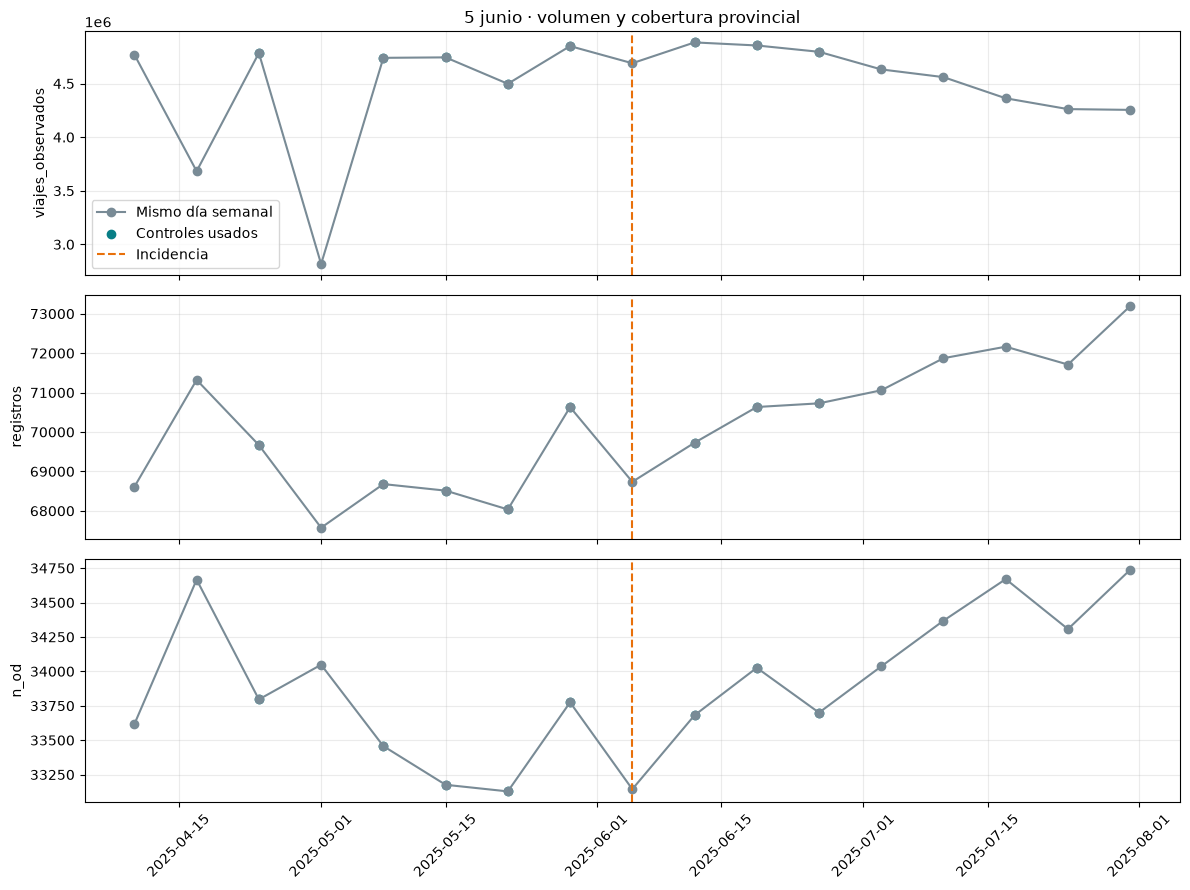

In [13]:
fecha_incidencia_junio = pd.Timestamp("2025-06-05")
movilidad_junio = cargar_totales(fecha_incidencia_junio)
jueves = movilidad_junio.loc[movilidad_junio["day"].dt.day_of_week.eq(3)].copy()
jueves["excluido_julio_agosto"] = jueves["day"].dt.month.isin(MESES_EXCLUIDOS)
display(jueves.round(2))
display(tabla_cobertura(movilidad_junio, fecha_incidencia_junio).round(2))
cobertura_junio = tabla_cobertura(movilidad_junio, fecha_incidencia_junio)
graficar_cobertura(movilidad_junio, fecha_incidencia_junio, "5 junio · volumen y cobertura provincial")

### 5.3. Relaciones de los corredores estudiados

Se conservan los municipios y ambos sentidos de las relaciones originales. Para cada OD se presenta observado, mediana, variación porcentual y P25/P75 de viajes. Los rangos y el número de controles ayudan a interpretar la referencia, sin convertirlos en pruebas de impacto causal.

In [14]:
municipios_junio = {"08121": "Mataró", "08096": "Granollers", "08088": "La Garriga",
                    "08187": "Sabadell", "08279": "Terrassa", "08056": "Castelldefels"}
relaciones_junio = {}
for codigo, nombre in municipios_junio.items():
    relaciones_junio[f"{nombre} → Barcelona"] = (codigo, "08019")
    relaciones_junio[f"Barcelona → {nombre}"] = ("08019", codigo)
movilidad_junio_od = cargar_relaciones(con, M2_PATH, relaciones_junio)
print("Relaciones:", movilidad_junio_od["Relacion"].nunique())

Relaciones: 12


In [15]:
comparacion_junio = comparar_relaciones(
    movilidad_junio_od, fecha_incidencia_junio, fechas_con_incidencias, festivos_cat)
display(comparacion_junio.drop(columns="fechas_controles").round(2))

,Relacion,municipio_origen,municipio_destino,fecha,viajes_observados,mediana_viajes_controles,p25_viajes_controles,p75_viajes_controles,n_controles,variacion_observada_pct,diferencia_viajes,fuera_rango_intercuartil_viajes,modo_controles,ventana_dias,minimo_controles,estado
0,Barcelona → Castelldefels,08019,08056,2025-06-05,14755.0,15787.0,15569.25,16772.50,8,-6.54,-1032.0,True,retrospectivo,42,3,ok
1,Mataró → Barcelona,08121,08019,2025-06-05,12275.0,12744.5,12236.00,12831.75,8,-3.68,-469.5,False,retrospectivo,42,3,ok
2,Terrassa → Barcelona,08279,08019,2025-06-05,18669.0,19265.5,18218.00,19541.75,8,-3.10,-596.5,False,retrospectivo,42,3,ok
3,Castelldefels → Barcelona,08056,08019,2025-06-05,14392.0,14773.0,14175.00,15341.75,8,-2.58,-381.0,False,retrospectivo,42,3,ok
4,Barcelona → Granollers,08019,08096,2025-06-05,9136.0,9361.0,9130.75,9425.50,8,-2.40,-225.0,False,retrospectivo,42,3,ok
5,Barcelona → Mataró,08019,08121,2025-06-05,13551.0,13845.0,13718.75,13891.00,8,-2.12,-294.0,True,retrospectivo,42,3,ok
6,Granollers → Barcelona,08096,08019,2025-06-05,9118.0,9201.5,8881.75,9334.00,8,-0.91,-83.5,False,retrospectivo,42,3,ok
7,Barcelona → La Garriga,08019,08088,2025-06-05,2007.0,2014.0,1963.50,2072.25,8,-0.35,-7.0,False,retrospectivo,42,3,ok
8,Barcelona → Sabadell,08019,08187,2025-06-05,22870.0,22880.0,22473.50,23179.75,8,-0.04,-10.0,False,retrospectivo,42,3,ok
9,Sabadell → Barcelona,08187,08019,2025-06-05,23951.0,23619.5,23386.00,24104.50,8,1.40,331.5,False,retrospectivo,42,3,ok


### 5.4. Visualización de la variación de viajes

La escala muestra porcentajes de viajes respecto a la mediana de días comparables. Un valor negativo significa menos viajes que esa referencia. No se representan puntos porcentuales de residuos ni cantidades atribuidas causalmente a Rodalies.

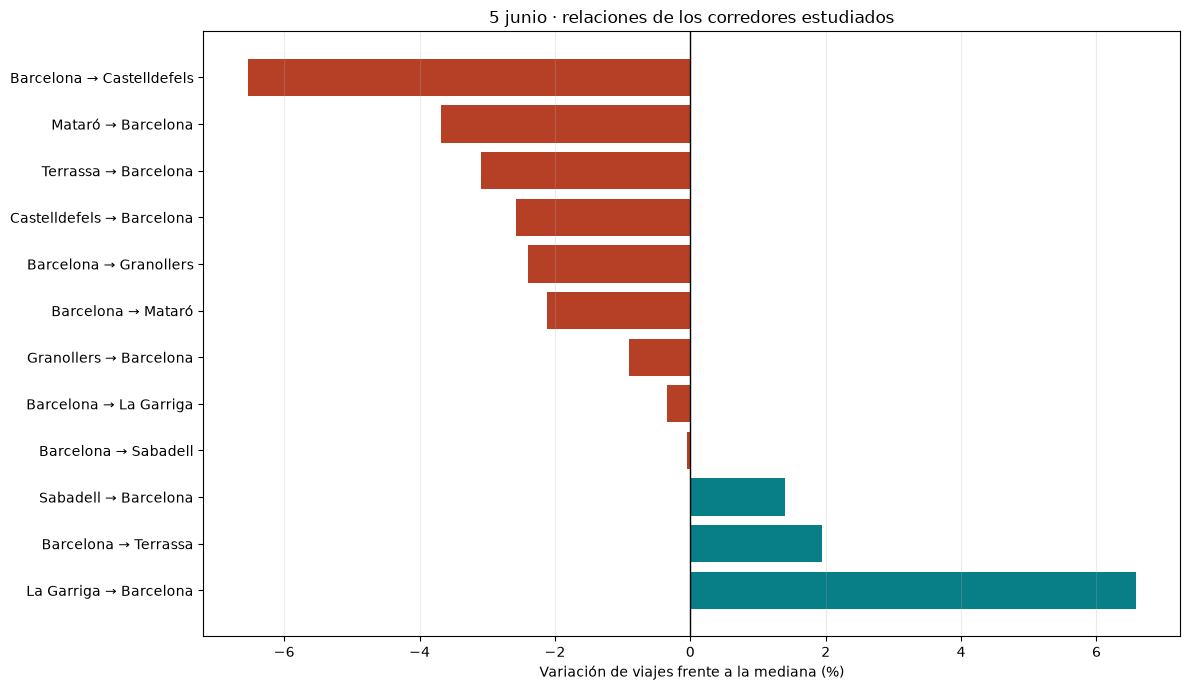

In [16]:
graficar_variacion(comparacion_junio, "5 junio · relaciones de los corredores estudiados")

### 5.5. Corredor sur: veinte OD

Se mantienen las veinte relaciones elegidas por territorio y volumen de 2024. Se aplica la misma regla a todas, sin seleccionar solo descensos. Julio y agosto se excluyen tanto de los objetivos como de sus días de referencia.

In [17]:
resultados_sur_junio = comparar_relaciones(
    movilidad_observada, fecha_incidencia_junio, fechas_con_incidencias, festivos_cat)
display(resultados_sur_junio.drop(columns="fechas_controles").round(2))

,Relacion,municipio_origen,municipio_destino,fecha,viajes_observados,mediana_viajes_controles,p25_viajes_controles,p75_viajes_controles,n_controles,variacion_observada_pct,diferencia_viajes,fuera_rango_intercuartil_viajes,modo_controles,ventana_dias,minimo_controles,estado
0,Gavà → Viladecans,08089,08301,2025-06-05,2834.0,3162.0,3059.00,3277.00,8,-10.37,-328.0,True,retrospectivo,42,3,ok
1,El Prat de Llobregat → Viladecans,08169,08301,2025-06-05,5947.0,6389.0,6103.25,6759.00,8,-6.92,-442.0,True,retrospectivo,42,3,ok
2,Barcelona → Castelldefels,08019,08056,2025-06-05,14755.0,15787.0,15569.25,16772.50,8,-6.54,-1032.0,True,retrospectivo,42,3,ok
3,Viladecans → Gavà,08301,08089,2025-06-05,2789.0,2936.5,2809.50,3109.50,8,-5.02,-147.5,True,retrospectivo,42,3,ok
4,El Prat de Llobregat → Castelldefels,08169,08056,2025-06-05,6289.0,6589.0,5845.75,7042.75,8,-4.55,-300.0,False,retrospectivo,42,3,ok
5,Barcelona → Viladecans,08019,08301,2025-06-05,16507.0,17237.5,16246.75,18249.75,8,-4.24,-730.5,False,retrospectivo,42,3,ok
6,Barcelona → Gavà,08019,08089,2025-06-05,10897.0,11295.0,10784.50,11685.00,8,-3.52,-398.0,False,retrospectivo,42,3,ok
7,Viladecans → El Prat de Llobregat,08301,08169,2025-06-05,6943.0,7177.5,6750.25,7655.25,8,-3.27,-234.5,False,retrospectivo,42,3,ok
8,Castelldefels → Barcelona,08056,08019,2025-06-05,14392.0,14773.0,14175.00,15341.75,8,-2.58,-381.0,False,retrospectivo,42,3,ok
9,Castelldefels → Viladecans,08056,08301,2025-06-05,7333.0,7514.0,7388.25,7641.25,8,-2.41,-181.0,True,retrospectivo,42,3,ok


### 5.6. Robustez: controles anteriores y retrospectivos

Se comparan dos estimandos descriptivos distintos: mediana de días anteriores y mediana de días anteriores/posteriores. La segunda utiliza futuro y no mide precisión predictiva.

No basta con un porcentaje: se muestran los controles y se evalúa la sensibilidad a ventanas de 28, 42 y 56 días. Cambiar los controles puede cambiar la magnitud; la estabilidad del signo se interpreta por separado. Un rango P25–P75 no es un intervalo de significación.

In [18]:
sur_predictivo, robustez, sensibilidad = analizar_robustez(
    movilidad_observada, fecha_incidencia_junio, fechas_con_incidencias, festivos_cat, resultados_sur_junio)
display(robustez.round(2))
display(sensibilidad[["Relacion", "modo_controles", "ventana_dias", "n_controles", "variacion_observada_pct"]].round(2))

,Relacion,variacion_observada_pct_retrospectivo,n_controles_retrospectivo,variacion_observada_pct_predictivo,n_controles_predictivo
0,Gavà → Viladecans,-10.37,8,-8.55,5
1,El Prat de Llobregat → Viladecans,-6.92,8,-9.37,5
2,Barcelona → Castelldefels,-6.54,8,-6.14,5
3,Viladecans → Gavà,-5.02,8,-2.65,5
4,El Prat de Llobregat → Castelldefels,-4.55,8,-4.45,5
5,Barcelona → Viladecans,-4.24,8,-8.80,5
6,Barcelona → Gavà,-3.52,8,-5.42,5
7,Viladecans → El Prat de Llobregat,-3.27,8,-7.95,5
8,Castelldefels → Barcelona,-2.58,8,-1.65,5
9,Castelldefels → Viladecans,-2.41,8,-1.97,5


,Relacion,modo_controles,ventana_dias,n_controles,variacion_observada_pct
0,El Prat de Llobregat → Viladecans,predictivo,28,4,-12.35
1,Viladecans → El Prat de Llobregat,predictivo,28,4,-10.43
2,Barcelona → Castelldefels,predictivo,28,4,-9.06
3,Barcelona → Viladecans,predictivo,28,4,-7.08
4,Gavà → Viladecans,predictivo,28,4,-6.13
...,...,...,...,...,...
115,El Prat de Llobregat → Castelldefels,retrospectivo,56,10,0.67
116,Viladecans → Castelldefels,retrospectivo,56,10,1.10
117,El Prat de Llobregat → Barcelona,retrospectivo,56,10,3.75
118,Gavà → Barcelona,retrospectivo,56,10,4.20


### 5.7. Evolución temporal y referencia local

Se conservan Barcelona → Castelldefels y Mataró → Barcelona. Los viajes se representan todos los días disponibles; la referencia solo se calcula en fechas elegibles. La mediana retrospectiva es una descripción histórica y no una predicción sin futuro.

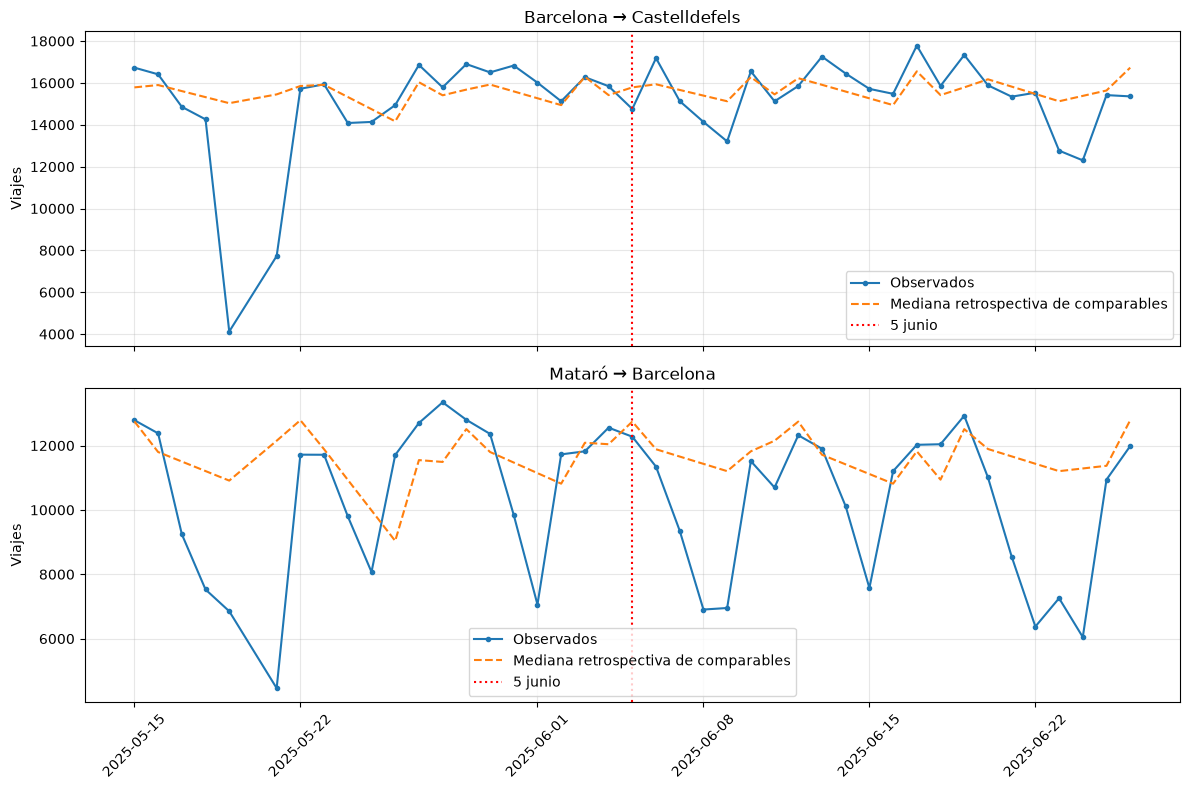

In [19]:
fecha = fecha_incidencia_junio
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, nombre in zip(axes, ["Barcelona → Castelldefels", "Mataró → Barcelona"]):
    g = movilidad_junio_od.loc[movilidad_junio_od["Relacion"].eq(nombre)].sort_values("day")
    serie = g.loc[g["day"].between(fecha-pd.Timedelta(days=21), fecha+pd.Timedelta(days=21))]
    refs = pd.DataFrame([calcular_indicadores(g, d, fechas_con_incidencias, festivos_cat)[0]
                         for d in serie["day"]])
    refs = refs.loc[refs["estado"].eq("ok")]
    ax.plot(serie["day"], serie["viajes_observados"], label="Observados", marker="o", markersize=3)
    ax.plot(pd.to_datetime(refs["fecha"]), refs["mediana_viajes_controles"],
            linestyle="--", label="Mediana retrospectiva de comparables")
    ax.axvline(fecha, color="red", linestyle=":", label="5 junio")
    ax.set(title=nombre, ylabel="Viajes"); ax.legend(); ax.grid(alpha=.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 5.8. Resultados territoriales y exportación

Se muestran la variación porcentual y los viajes observados frente a la distribución de controles. Los percentiles se expresan en viajes, no en residuos ni puntos porcentuales. No se consideran un contraste estadístico de incidencia.

La referencia queda auditada mediante las fechas, el número de controles, el calendario excluido y el modo de comparación.

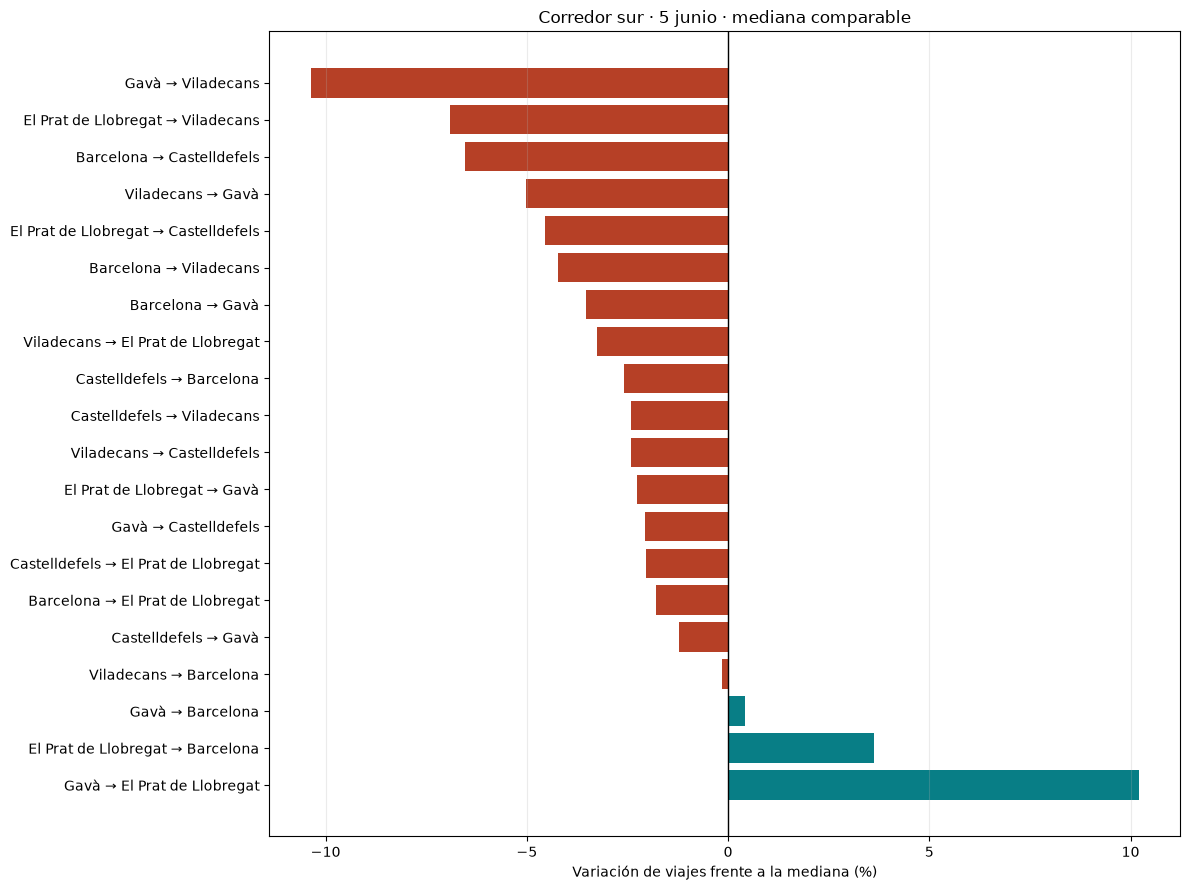

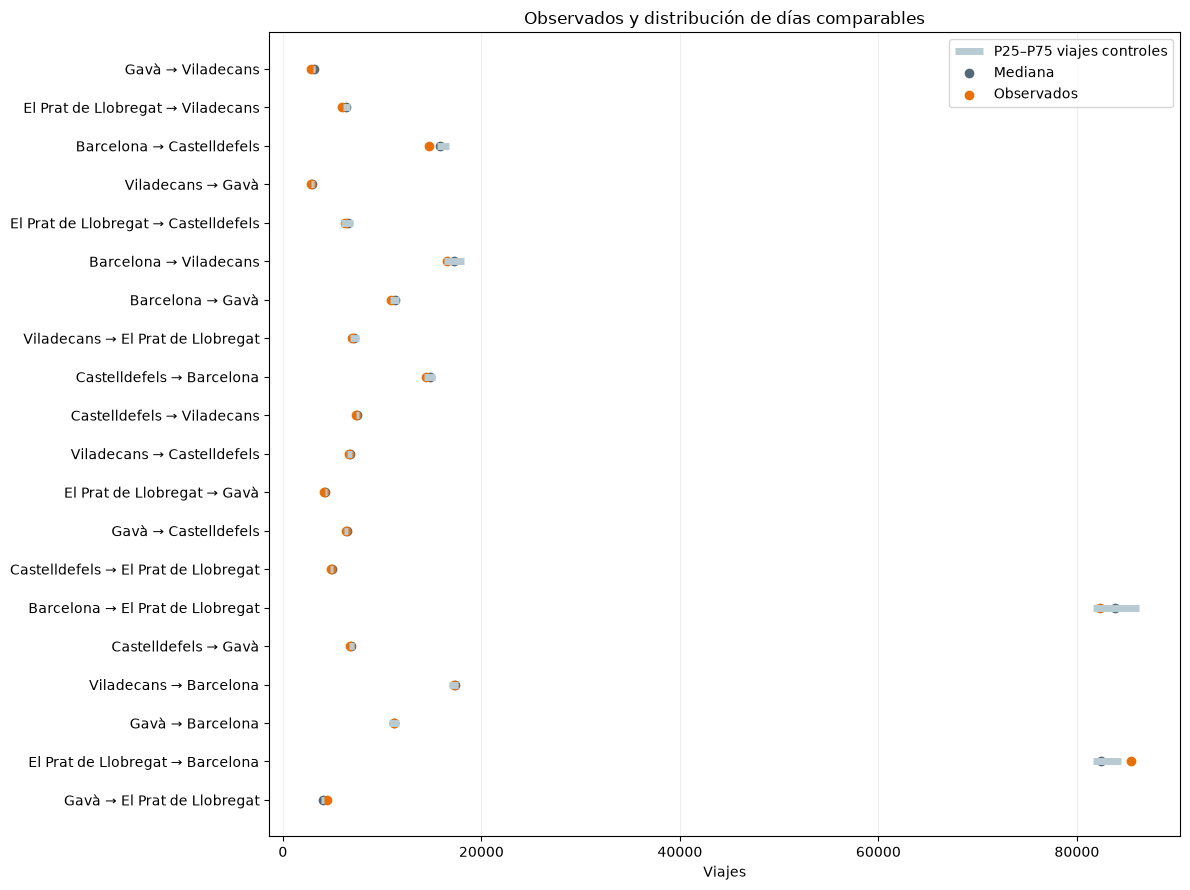

In [20]:
graficar_variacion(resultados_sur_junio, "Corredor sur · 5 junio · mediana comparable", alto=9)
orden = resultados_sur_junio.sort_values("variacion_observada_pct")
fig, ax = plt.subplots(figsize=(12, 9))
y = np.arange(len(orden))
ax.hlines(y, orden["p25_viajes_controles"], orden["p75_viajes_controles"],
          color="#b9cbd2", linewidth=5, label="P25–P75 viajes controles")
ax.scatter(orden["mediana_viajes_controles"], y, label="Mediana", color="#536979")
ax.scatter(orden["viajes_observados"], y, label="Observados", color="#e8700a")
ax.set_yticks(y, orden["Relacion"]); ax.invert_yaxis()
ax.set(xlabel="Viajes", title="Observados y distribución de días comparables")
ax.legend(); ax.grid(axis="x", alpha=.2)
plt.tight_layout(); plt.show()

In [21]:
disponibilidad_junio = evaluar_disponibilidad(
    movilidad_observada, relaciones_sur_dict, fecha_incidencia_junio, fechas_con_incidencias, festivos_cat)
catalogo_junio = [
    {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
    {"codigo": "08056", "nombre": "Castelldefels", "lat": 41.281, "lon": 1.976},
    {"codigo": "08089", "nombre": "Gavà", "lat": 41.306, "lon": 2.001},
    {"codigo": "08301", "nombre": "Viladecans", "lat": 41.315, "lon": 2.019},
    {"codigo": "08169", "nombre": "El Prat de Llobregat", "lat": 41.327, "lon": 2.094},
]
for municipio in catalogo_junio:
    municipio["precision"] = "Posición municipal aproximada; no es una estación"
salida_junio = exportar_caso(
    output_dir=output_dir, fecha=fecha_incidencia_junio, ficha=ficha_junio,
    ambito="Corredor sur", municipios=catalogo_junio, resultados=resultados_sur_junio,
    movilidad=movilidad_observada, disponibilidad=disponibilidad_junio,
    provincia=movilidad_junio, cobertura=cobertura_junio,
    robustez=robustez, sensibilidad=sensibilidad,
    fechas_incidencias=fechas_con_incidencias, festivos=festivos_cat,
    fuente_excel=str(INCIDENCIAS_PATH.relative_to(PROJECT_ROOT)),
    descripcion="Incidencia ferroviaria en Barcelona")
print("Exportado: incidencia_2025_06_05.json")
display(resultados_sur_junio.loc[resultados_sur_junio["Relacion"].isin(
    ["Gavà → Viladecans", "Barcelona → Castelldefels"])].drop(columns="fechas_controles").round(2))
for texto in conclusiones_caso(resultados_sur_junio, cobertura_junio):
    print("•", texto)

Exportado: incidencia_2025_06_05.json


,Relacion,municipio_origen,municipio_destino,fecha,viajes_observados,mediana_viajes_controles,p25_viajes_controles,p75_viajes_controles,n_controles,variacion_observada_pct,diferencia_viajes,fuera_rango_intercuartil_viajes,modo_controles,ventana_dias,minimo_controles,estado
0,Gavà → Viladecans,08089,08301,2025-06-05,2834.0,3162.0,3059.00,3277.0,8,-10.37,-328.0,True,retrospectivo,42,3,ok
2,Barcelona → Castelldefels,08019,08056,2025-06-05,14755.0,15787.0,15569.25,16772.5,8,-6.54,-1032.0,True,retrospectivo,42,3,ok


• 20 relaciones con comparación válida: 17 por debajo de la mediana y 3 por encima.
• Menor variación: Gavà → Viladecans (-10,37 %).
• Mayor variación: Gavà → El Prat de Llobregat (+10,20 %).
• Variación de viajes provinciales frente a sus días comparables: -2,11 %.
• Variación de registros de movilidad frente a sus días comparables: -1,38 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.


## 6. Alcance y calidad de datos

Las dos incidencias se estudian con las mismas reglas y conservan la documentación original del Excel. Los días sin incidencia registrada no garantizan normalidad; las series y los recuentos de registros/OD permiten investigar anomalías generales de cobertura o movilidad.

Los datos diarios no identifican modo, horarios ni usuarios afectados. Las conclusiones se limitan a diferencias de viajes respecto a comparables; no demuestran causalidad ni significación estadística. Los nodos cartográficos son posiciones municipales aproximadas, no estaciones ni itinerarios ferroviarios.